# H11. PS4 위장 결측이 냉각기 상태와 관련 있는가 (라벨 누수)

| 항목 | 내용 |
|---|---|
| 질문 | PS4가 60초 내내 0인(고장 난) 사이클이 특정 냉각기 상태에 몰려 있을까? |
| 귀무가설 H0 | PS4 고장 여부는 부품 상태와 독립이다 |
| 대립가설 H1 | PS4 고장 여부가 부품 상태와 관련 있다 |
| 검정 | 카이제곱 독립성 검정 (부품 4개 → Holm), Cramér's V |
| 출처 (EDA) | F04 PS4 위장 결측 |
| 데이터 | 원본 PS4.txt → 60초 내내 0인지 여부 |
| 왜 중요한가 | PS4를 그대로 쓰면 AI가 엉터리 규칙(지름길)을 배우는지 |

**진행 순서:** 1 EDA 시각화 → 2 기술통계 → 3 가정 확인 → 4 정상성 확인 → 5 가설검정(p-값) → 6 사후검정·효과 크기 → 7 블록 평균 재확인 → 8 최종 판정 → 9 해석과 결정

유의수준은 **α = 0.05**로 미리 정했습니다. 표본이 2,205개로 커서 작은 차이도 p < 0.05가 되므로, **결론은 효과 크기와 함께** 내립니다.

In [1]:
from common import *
cyc = load_cycles()
print(cyc.shape)

(2205, 75)


## 1. EDA 시각화

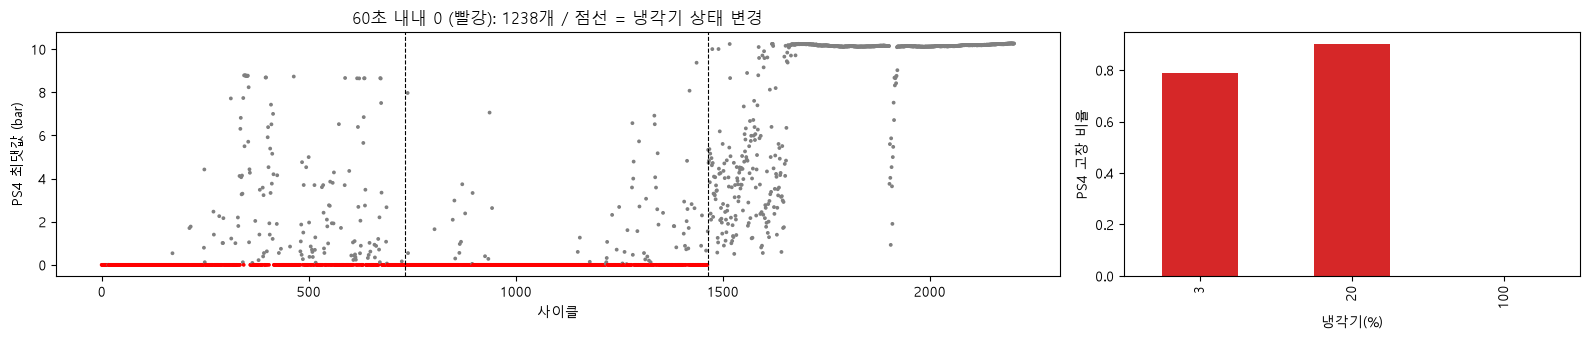

In [2]:
ps4 = raw("PS4"); dead = (ps4 == 0).all(axis=1); cyc["PS4_dead"] = dead.astype(int)
fig, axes = plt.subplots(1, 2, figsize=(16, 3.5), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].scatter(cyc["cycle"], ps4.max(axis=1), s=3, c=np.where(dead, "red", "gray")); axes[0].set_xlabel("사이클"); axes[0].set_ylabel("PS4 최댓값 (bar)")
for x in [732, 1464]: axes[0].axvline(x, color="k", ls="--", lw=0.8)
axes[0].set_title(f"60초 내내 0 (빨강): {dead.sum()}개 / 점선 = 냉각기 상태 변경")
cyc.groupby("cooler_pct")["PS4_dead"].mean().plot.bar(ax=axes[1], color="C3"); axes[1].set_ylabel("PS4 고장 비율"); axes[1].set_xlabel(COMP["cooler_pct"])
plt.tight_layout(); plt.show()

**EDA로 본 것:** PS4 고장은 냉각기 3%·20% 구간에만 있고 100% 구간에는 없습니다.

## 2. 기술통계

In [3]:
for c in COMP: print(COMP[c], cyc.groupby(c)['PS4_dead'].mean().round(2).to_dict())

냉각기(%) {3: 0.79, 20: 0.9, 100: 0.0}
밸브(%) {73: 0.52, 80: 0.56, 90: 0.53, 100: 0.58}
펌프 누설 {0: 0.6, 1: 0.51, 2: 0.51}
축압기(bar) {90: 0.48, 100: 0.5, 115: 0.52, 130: 0.74}


## 3. 가정 확인 (기대빈도 ≥ 5)

In [4]:
for c in COMP: print(COMP[c], '최소 기대빈도 =', round(cramers_v(pd.crosstab(cyc['PS4_dead'], cyc[c]))['min_expected'], 1))

냉각기(%) 최소 기대빈도 = 321.0
밸브(%) 최소 기대빈도 = 157.9
펌프 누설 최소 기대빈도 = 215.8
축압기(bar) 최소 기대빈도 = 175.0


## 4. 정상성 대신: 시간 배치 확인

PS4 고장 여부(0/1)를 100사이클 이동평균으로 그려, 시간에 따라 몰려 있는지 봅니다.

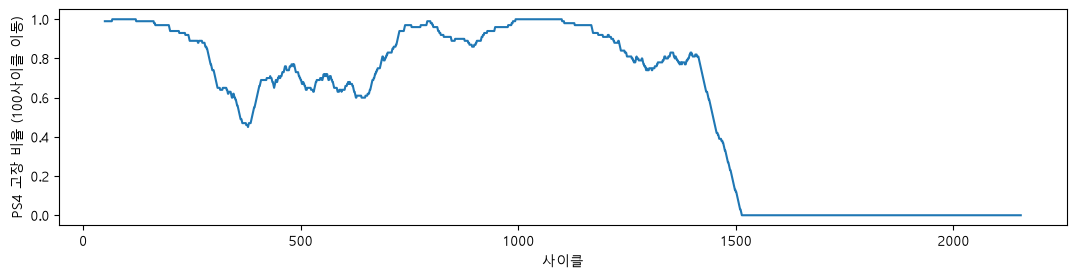

0/1 값이라 ADF·KPSS 대신 이동 비율로 시간 배치를 봅니다. 냉각기 100% 구간(1464~)에서 0으로 떨어지면 시간·상태와 겹친 것입니다.


In [5]:
fig, ax = plt.subplots(figsize=(13, 2.8)); ax.plot(cyc["cycle"], cyc["PS4_dead"].rolling(100, center=True).mean())
ax.set_ylabel("PS4 고장 비율 (100사이클 이동)"); ax.set_xlabel("사이클"); plt.show()
print("0/1 값이라 ADF·KPSS 대신 이동 비율로 시간 배치를 봅니다. 냉각기 100% 구간(1464~)에서 0으로 떨어지면 시간·상태와 겹친 것입니다.")

## 5. 가설검정 (p-값)

In [6]:
res = pd.DataFrame([dict(부품=COMP[c], **cramers_v(pd.crosstab(cyc["PS4_dead"], cyc[c]))) for c in COMP])
res["p_holm"] = holm(res["p"]); res["효과"] = res["V"].map(lambda v: size_label(v, "V"))
display(res.style.format({"chi2": "{:.1f}", "p": "{:.2e}", "p_holm": "{:.2e}", "V": "{:.3f}", "min_expected": "{:.0f}"}))

,부품,chi2,df,p,V,min_expected,p_holm,효과
0,냉각기(%),1447.5,2,0.00e+00,0.810,321,0.00e+00,큼
1,밸브(%),5.3,3,1.54e-01,0.049,158,1.54e-01,매우 작음
2,펌프 누설,19.7,2,5.15e-05,0.095,216,1.03e-04,매우 작음
3,축압기(bar),112.1,3,3.82e-24,0.226,175,1.14e-23,작음


## 6. 효과 크기: 지름길이 얼마나 강한가

"PS4가 0이면 냉각기 불량(3% 또는 20%)"이라는 규칙 하나로 맞히는 비율을 봅니다.

In [7]:
rule = np.where(cyc["PS4_dead"] == 1, "불량(3·20%)", "정상(100%)"); truth = np.where(cyc["cooler_pct"] < 100, "불량(3·20%)", "정상(100%)")
display(pd.crosstab(pd.Series(rule, name="PS4 규칙"), pd.Series(truth, name="실제 냉각기")))
print(f"PS4 하나로 냉각기 정상/불량 맞힘: {(rule == truth).mean():.1%}  (냉각기 불량을 놓치지 않는 비율 {((rule == truth) & (truth == '불량(3·20%)')).sum() / (truth == '불량(3·20%)').sum():.1%})")

실제 냉각기,불량(3·20%),정상(100%)
PS4 규칙,,
불량(3·20%),1238,0
정상(100%),226,741


PS4 하나로 냉각기 정상/불량 맞힘: 89.8%  (냉각기 불량을 놓치지 않는 비율 84.6%)


## 7. 재확인: 블록 단위

50사이클 블록마다 PS4 고장 비율을 내고, 냉각기 상태별로 Kruskal-Wallis로 비교합니다.

In [8]:
b = block_means(cyc, "PS4_dead", "cooler_pct"); rb = kruskal_test(b["PS4_dead"], b["cooler_pct"])
print(f"블록 {len(b)}개: H = {rb['H']:.1f}, p = {rb['p']:.2e}, ε² = {rb['eps2']:.2f}")

블록 47개: H = 33.6, p = 5.06e-08, ε² = 0.73


## 8. 최종 판정

In [9]:
r0 = res.iloc[0]
final = pd.DataFrame([dict(가설="H11", 검정="카이제곱", 통계량=f"χ²({int(r0.df)}) = {r0.chi2:.0f}", p_holm=r0.p_holm, 효과크기=f"V = {r0.V:.2f} ({r0.효과})",
    블록_p=rb["p"], 판정="H0 기각 (누수 위험)" if r0.p_holm < ALPHA else "H0 유지")])
display(final)
save_result("H11", title="PS4 위장 결측 × 냉각기 (누수)", test="카이제곱", stat=final.통계량[0], p=r0.p_holm, effect=final.효과크기[0], verdict=final.판정[0])

,가설,검정,통계량,p_holm,효과크기,블록_p,판정
0,H11,카이제곱,χ²(2) = 1447,0.0,V = 0.81 (큼),5.060950e-08,H0 기각 (누수 위험)


저장: results/H11.json


## 9. 해석과 결정

- PS4 고장과 냉각기 상태의 관련이 매우 강합니다(V ≈ 0.81). 냉각기 100%에서는 PS4 고장이 한 번도 없습니다.
- 그래서 PS4를 그대로 쓰면 AI가 **"PS4가 0이면 냉각기 불량"**이라는, 현장에서는 통하지 않는 규칙을 배웁니다(라벨 누수).
- **결정:** 전처리(WBS 2.2.2, 11/27)에서 **PS4를 특징에서 빼거나 최소한 냉각기 모델에서 제외**합니다. 딥러닝 비교(99번)에서도 PS4는 입력에서 뺐습니다.